# 🚀 Исследование стартапов

**Автор:** Волкова Анастасия Викторовна 🌸

**Дата:** 27.02.2026

## 📄 Введение

🎯 **Цели и задачи проекта**

Цель: проанализировать исторические данные о финансировании стартапов, чтобы выявить закономерности и оценить перспективы инвестиций в венчурный сектор. На основе анализа дать рекомендации по оптимальным направлениям и типам инвестирования.

Задачи:

- Загрузка и предобработка данных:

    - загрузить и изучить датасеты cb_investments.csv и cb_returns.csv
    - проверить и исправить типы данных, обработать пропуски и дубликаты, отфильтровать нерелевантные строки
    - привести к единому формату названия столбцов, даты, числовые значения
    
- Инжиниринг признаков:

    - сгруппировать компании по срокам финансирования
    - классифицировать сегменты рынка
    
- Анализ выбросов и фильтрация:

    - проанализировать и пометить выбросы в каждом из сегментов
    - ограничить период анализа, исключить
    - проанализировать типы финансирования по объему и популярности

- Динамический анализ:

    - проследить изменения среднего размера раунда и количества раундов по годам
    - проанализировать динамику финансирования по массовым сегментам рынка
    - рассчитать и визуализировать долю возвращённых средств по типам финансирования за каждый год

- Формулировка выводов и рекомендаций:

    - определить наиболее перспективные отрасли и типы финансирования на 2015 г.
    - подвести итоги проведённого анализа

📝 **Содержимое проекта**

- Данные:

    - `cb_investments.csv` — информация о компаниях, раундах финансирования, объёмах инвестиций, статусе, географии и сегментах рынка;
    - `cb_returns.csv` — данные о возвратах средств по годам и типам финансирования (в млн долл.).

- Этапы работы:

    - загрузка, обзор и предобработка данных.
    - создание новых признаков (группы по срокам, сегментация рынков).
    - выявление и обработка выбросов, ограничение периода анализа.
    - сравнительный анализ типов финансирования (объёмы, популярность, возвраты).
    - анализ динамики по годам и сегментам.

- Итоговый вывод и рекомендации:

    - обобщение результатов анализа
    - формулировка ключевых выводов


## 1️⃣ Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.




---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### 1.1. Вывод общей информации

In [2]:
#Выгружаем данные
cb_investments = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)
cb_returns = pd.read_csv('https://code.s3.yandex.net/datasets/cb_returns.csv')

*Знакомство с данными датафрейма cb_investments:*



In [3]:
# Выводим первые строки датафрейма
cb_investments.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
# Выводим информацию о датафрейме
cb_investments.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

*Знакомство с данными датафрейма cb_returns:*


In [5]:
# Выводим первые строки датафрейма
cb_returns.head()

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
1,2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2,2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
3,2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
4,2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [6]:
# Выводим информацию о датафрейме
cb_returns.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


    
**Промежуточный вывод**

cb_investments:

Объём: 54 294 строки, 40 столбцов.

Данные соответствуют описанию.

Пропуски присутствуют в каждом столбце.

Типы данных:

- даты (`founded_at`, `first_funding_at` и др.) — object (нужно в datetime);
- `funding_total_usd` — object, нужно перевести в числовой тип;

Особенности: в названиях столбцов есть пробелы.

cb_returns:

Объём: 15 строк (по годам), 14 столбцов.

Данные соответствуют описанию.

Пропуски - отсутствуют.

Типы данных корректные.


### 1.2. Предобработка данных

In [7]:
#Введем переменные total_rows для посчета количества строк в датафреймах до предобработки данных
total_rows_cb_investments = len(cb_investments)
print(total_rows_cb_investments)
total_rows_cb_returns = len(cb_returns)
print(total_rows_cb_returns)

54294
15


In [8]:
#Проверим названия столбцов
cb_investments.columns

Index(['name', 'homepage_url', 'category_list', ' market ',
       ' funding_total_usd ', 'status', 'country_code', 'state_code', 'region',
       'city', 'funding_rounds', 'participants', 'founded_at', 'founded_month',
       'founded_quarter', 'founded_year', 'first_funding_at', 'mid_funding_at',
       'last_funding_at', 'seed', 'venture', 'equity_crowdfunding',
       'undisclosed', 'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding', 'round_A', 'round_B',
       'round_C', 'round_D', 'round_E', 'round_F', 'round_G', 'round_H'],
      dtype='object')

In [9]:
#Проверим названия столбцов
cb_returns.columns

Index(['year', 'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
       'convertible_note', 'debt_financing', 'angel', 'grant',
       'private_equity', 'post_ipo_equity', 'post_ipo_debt',
       'secondary_market', 'product_crowdfunding'],
      dtype='object')

In [10]:
#Уберем пробелы в названиях столбцов
cb_investments.columns = cb_investments.columns.str.strip()

In [11]:
#Убираем запятые в funding_total_usd
cb_investments['funding_total_usd'] = cb_investments['funding_total_usd'].str.replace(',', '', regex=False)

#Преобразовываем funding_total_usd в числовой тип, некорректные значения становятся NaN
cb_investments['funding_total_usd'] = pd.to_numeric(cb_investments['funding_total_usd'], errors='coerce')


In [12]:
# Проверим результат
print(cb_investments['funding_total_usd'].head())
print(cb_investments['funding_total_usd'].dtype)

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
Name: funding_total_usd, dtype: float64
float64


In [13]:
# Список столбцов с датами, которые нужно преобразовать
date_columns = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

# Преобразуем каждый столбец в datetime, некорректные значения станут NaT
for col in date_columns:
    if col in cb_investments.columns:
        cb_investments[col] = pd.to_datetime(cb_investments[col], errors='coerce')

# Проверим результат
print(cb_investments[date_columns].dtypes)

# Посмотрим примеры значений
print(cb_investments[date_columns].head())

founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
dtype: object
  founded_at first_funding_at mid_funding_at last_funding_at
0        NaT       2014-01-06            NaT      2014-01-06
1 1785-01-01       2014-05-15            NaT      2014-05-15
2 1802-07-19       2009-07-02     2009-07-02      2009-07-02
3 1817-01-01       2013-11-21     2013-11-21      2014-11-03
4 1826-01-01       2014-01-14            NaT      2014-01-14


In [14]:
# Сделаем столбец 'year' индексом
cb_returns = cb_returns.set_index('year')

In [15]:
# Столбцы с текстовыми данными, которые необходимо преобразовать
columns_to_normalize = ['name', 'market', 'category_list', 'status', 'region', 'city']
# Убираем пробелы и приводим к нижнему регистру
for col in columns_to_normalize:
    if col in cb_investments.columns:
        cb_investments[col] = cb_investments[col].str.lower().str.strip()

In [16]:
# Проверим дубликаты
print(f"Количество полных дубликатов: {cb_investments.duplicated().sum()}")
# Сохраним количество строк до удаления
rows_before = len(cb_investments)
#Удалим полные дубликаты
cb_investments = cb_investments.drop_duplicates(keep='first')
# Посмотрим результат
rows_after = len(cb_investments)
removed_duplicates = rows_before - rows_after
print(f"Удалено дубликатов: {removed_duplicates}")
print(f"Осталось строк: {rows_after}")

Количество полных дубликатов: 4855
Удалено дубликатов: 4855
Осталось строк: 49439


In [17]:
# Проверим количество пропусков в funding_total_usd
missing_funding = cb_investments['funding_total_usd'].isna().sum()
total_rows = len(cb_investments)
print(f"Пропусков в funding_total_usd: {missing_funding}")
print(f"Всего строк: {total_rows}")
print(f"Процент пропусков: {round(missing_funding/total_rows*100, 2)}%")

Пропусков в funding_total_usd: 8532
Всего строк: 49439
Процент пропусков: 17.26%


In [18]:
# Удалим строки, которые не несут какой-либо информации либо не содержат данных о финансировании
cb_investments = cb_investments.dropna(subset=['funding_total_usd'])
cb_investments = cb_investments[cb_investments['funding_total_usd'] > 0]
cb_investments = cb_investments[cb_investments['funding_rounds'] > 0]

# Помсотрим результат
print(f"Пропусков в funding_total_usd: {cb_investments['funding_total_usd'].isna().sum()}")
print(f"Строк с нулевым финансированием: {(cb_investments['funding_total_usd'] == 0).sum()}")
print(f"Строк без раундов финансирования: {(cb_investments['funding_rounds'] == 0).sum()}")

Пропусков в funding_total_usd: 0
Строк с нулевым финансированием: 0
Строк без раундов финансирования: 0


In [19]:
# Проверим количество пропусков в mid_funding_at
missing_mid = cb_investments['mid_funding_at'].isna().sum()
total_rows = len(cb_investments)
print(f"Пропусков в mid_funding_at: {missing_mid}")
print(f"Всего строк: {total_rows}")
print(f"Процент пропусков: {round(missing_mid/total_rows*100, 2)}%")


Пропусков в mid_funding_at: 13676
Всего строк: 40907
Процент пропусков: 33.43%


In [20]:
# Создадим маску для строк, где mid_funding_at пропущен, но есть обе даты
mask = (
    cb_investments['mid_funding_at'].isna() & 
    cb_investments['first_funding_at'].notna() & 
    cb_investments['last_funding_at'].notna()
)

first_dates = cb_investments.loc[mask, 'first_funding_at']
last_dates = cb_investments.loc[mask, 'last_funding_at']

# Вычисляем середину интервала
mid_dates = first_dates + (last_dates - first_dates) / 2

# Заполняем пропуски
cb_investments.loc[mask, 'mid_funding_at'] = mid_dates

print(f"Заполнено пропусков в mid_funding_at: {mask.sum()}")

Заполнено пропусков в mid_funding_at: 13675


In [21]:
# Проверим, сколько пропусков осталось
remaining_missing = cb_investments['mid_funding_at'].isna().sum()
print(f"Оставшиеся пропуски в mid_funding_at: {remaining_missing}")

Оставшиеся пропуски в mid_funding_at: 1


In [22]:
# Найдем строку с оставшимся пропуском
remaining_mask = cb_investments['mid_funding_at'].isna()
remaining_row = cb_investments[remaining_mask]

print(remaining_row[['first_funding_at', 'mid_funding_at', 'last_funding_at']])

      first_funding_at mid_funding_at last_funding_at
33041              NaT            NaT      2014-09-25


In [23]:
#Удалим строку с пропуском mid_funding_at
cb_investments = cb_investments.dropna(subset=['mid_funding_at'])

In [24]:
# Исходное количество строк в cb_investments
initial_rows = 54294
# Общее количество удаленных строк 
total_dropped = 4855 + 8532 + 1

percentage_dropped = round((total_dropped / initial_rows) * 100, 2)

final_rows = initial_rows - total_dropped

print(f"Исходное количество строк в cb_investments: {initial_rows}")
print(f"Всего удалено строк: {total_dropped}")
print(f"Процент удаленных данных: {percentage_dropped}%")
print(f"Финальное количество строк: {final_rows}")

Исходное количество строк в cb_investments: 54294
Всего удалено строк: 13388
Процент удаленных данных: 24.66%
Финальное количество строк: 40906


**Вывод после предобработки данных**

Изначальный объем данных: в `cb_investments` 54294 строки, в `cb_returns` 15 строк.

В ходе предобработки из `cb_investments` были удалены полные дубликаты и строки, которые не несут какой-либо информации либо не содержат данных о финансировании, также удалены одна строка с пропуском `missing_mid`, что в сумме составляет 24.66% удаленных данных.

Столбцы приведены к корректным типам данных, текстовые данные нормализованы. Убрано выделение разрядов в столбце `funding_total_usd`. Заполнены пропуски в столбце `mid_funding_at`.

Данные полностью готовы для решения задач проекта. Оставшийся объем содержит качественную и релевантную информацию о компаниях, достаточную для дальнейшего анализа.


---

## 2️⃣ Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделение всех компаний на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.


In [25]:
# Создадим новую колонку для группировки
def categorize_funding_duration(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif pd.notna(row['first_funding_at']) and pd.notna(row['last_funding_at']):
        # Вычисляем разницу в днях
        duration_days = (row['last_funding_at'] - row['first_funding_at']).days
        if duration_days <= 365:
            return 'Срок финансирования до года'
        else:
            return 'Срок финансирования более года'
    else:
        return 'Не определено'

# Применяем функцию
cb_investments['funding_duration_group'] = cb_investments.apply(categorize_funding_duration, axis=1)

# Проверим распределение
print("Распределение компаний по группам:")
print(cb_investments['funding_duration_group'].value_counts())


Распределение компаний по группам:
Единичное финансирование          24113
Срок финансирования более года    12291
Срок финансирования до года        4501
Не определено                         1
Name: funding_duration_group, dtype: int64


In [26]:
# Найдем и посмотрим строку с группой "Не определено"
undefined_rows = cb_investments[cb_investments['funding_duration_group'] == 'Не определено']

print(undefined_rows[['first_funding_at', 'mid_funding_at', 'last_funding_at']])


     first_funding_at mid_funding_at last_funding_at
2177              NaT     2012-07-24      2012-07-24


In [27]:
# Удаляем строку с неопределенной группой
cb_investments = cb_investments[cb_investments['funding_duration_group'] != 'Не определено']

In [28]:
# Введем единую цветовую палитру для графиков
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']
group_names = ['Единичное финансирование', 'Срок финансирования до года', 'Срок финансирования более года']

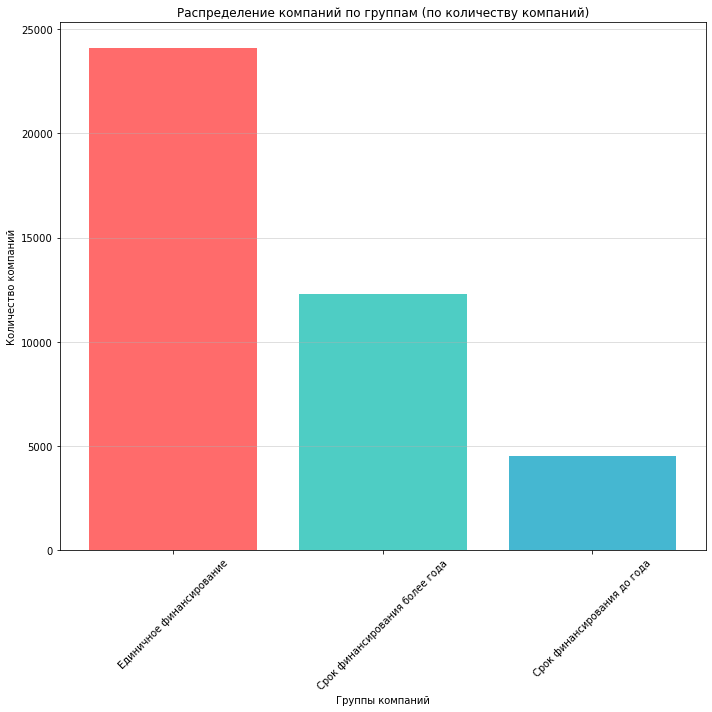

In [29]:
# Создаем столбчатую диаграмму по количеству компаний
plt.figure(figsize=(10, 10))

group_counts = cb_investments['funding_duration_group'].value_counts()

plt.bar(range(len(group_counts)), group_counts.values, color=colors)
plt.xlabel('Группы компаний')
plt.ylabel('Количество компаний')
plt.title('Распределение компаний по группам (по количеству компаний)')
plt.xticks(range(len(group_counts)), group_counts.index, rotation=45)
plt.grid(axis='y', alpha=0.5)

plt.tight_layout()
plt.show()


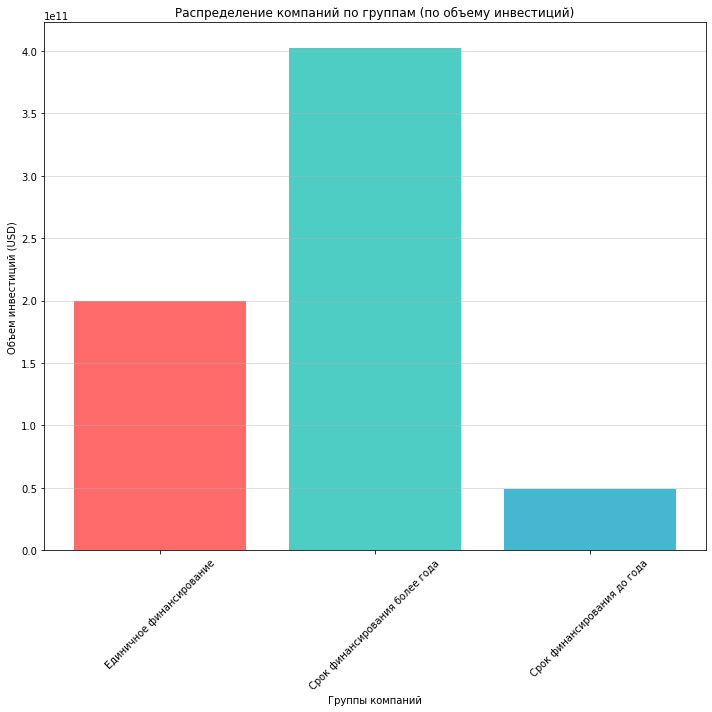

In [30]:
# Создаем столбчатую диаграмму по объему инвестиций
plt.figure(figsize=(10, 10))

group_funding = cb_investments.groupby('funding_duration_group')['funding_total_usd'].sum()

plt.bar(range(len(group_funding)), group_funding.values, color=colors)
plt.xlabel('Группы компаний')
plt.ylabel('Объем инвестиций (USD)')
plt.title('Распределение компаний по группам (по объему инвестиций)')
plt.xticks(range(len(group_funding)), group_funding.index, rotation=45)
plt.grid(axis='y', alpha=0.5)

plt.tight_layout()
plt.show()

Большинство компаний имеют единичное финансирование, а меньшиство - срок финансирования до года. Самые большие инвестиции в компаниях со сроком финансирования более года, а меньше всего с финансированием до года.

### 2.2 Выделение средних и нишевых сегментов рынка

In [31]:
# Подсчитаем количество компаний в каждом сегменте
market_counts = cb_investments['market'].value_counts()
print(market_counts.head(10))

software               4812
biotechnology          3590
mobile                 2344
e-commerce             1866
curated web            1693
enterprise software    1381
health care            1185
clean technology       1180
games                  1117
advertising            1107
Name: market, dtype: int64


In [32]:
# Классифицируем сегменты
def classify_market(count):
    if count > 120:
        return 'массовый'
    elif 35 <= count <= 120:
        return 'средний'
    else:
        return 'нишевый'

# Применяем классификацию
market_classification = market_counts.apply(classify_market)

# Подсчитаем количество сегментов в каждой категории
category_counts = market_classification.value_counts()
print(f"Количество сегментов в каждой категории:")
for category, count in category_counts.items():
    print(f"{category}: {count} сегментов")

# Подсчитаем общее количество компаний в каждой категории
companies_by_category = market_classification.groupby(market_classification).apply(
    lambda x: market_counts[x.index].sum()
)
print()
print(f"Общее количество компаний в каждой категории:")
for category, count in companies_by_category.items():
    print(f"{category}: {count:,} компаний")

Количество сегментов в каждой категории:
нишевый: 289 сегментов
средний: 57 сегментов
массовый: 48 сегментов

Общее количество компаний в каждой категории:
массовый: 33,733 компаний
нишевый: 830 компаний
средний: 3,839 компаний


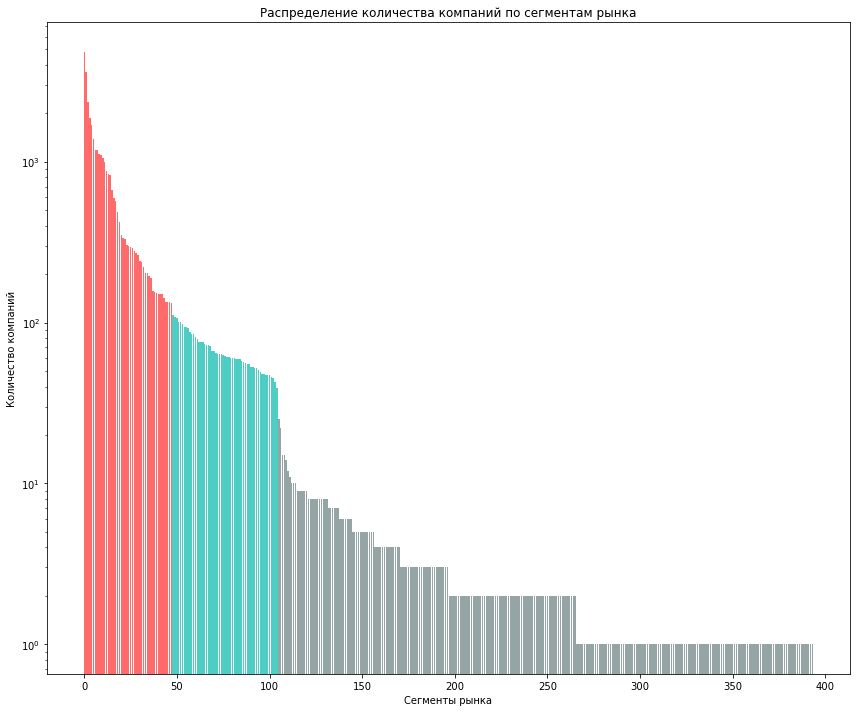

In [33]:
plt.figure(figsize=(12, 10))

# Сортируем сегменты по убыванию количества компаний
sorted_markets = market_counts.sort_values(ascending=False)

# Создаем цветовую палитру
colors = []
for count in sorted_markets.values:
    if count > 120:
        colors.append('#FF6B6B') # массовые - красный
    elif 35 <= count <= 120:
        colors.append('#4ECDC4') # средние - синий
    else:
        colors.append('#95A5A6') # нишевые - серый

bars = plt.bar(range(len(sorted_markets)), sorted_markets.values, color=colors)

plt.yscale('log') # Устанавливаем логарифмическую шкалу для лучшей визуализации

plt.xlabel('Сегменты рынка')
plt.ylabel('Количество компаний')
plt.title('Распределение количества компаний по сегментам рынка')
plt.tight_layout()

plt.show()

По графику видно, что наименьшее количество сегментов являются массовыми, т.е. имеют наибольшее количество компаний. Большинство сегментов являются нишевыми.

In [34]:
def replace_market_segment(market_name):
    if market_name in market_counts.index:
        count = market_counts[market_name]
        if count > 120:
            return market_name
        elif 35 <= count <= 120:
            return 'mid'
        else:
            return 'niche'
    else:
        return 'niche'

cb_investments['market'] = cb_investments['market'].apply(replace_market_segment)


---

## 3️⃣ Работа с выбросами и анализ

### 3.1. Анализ и выявление выбросы в каждом из сегментов


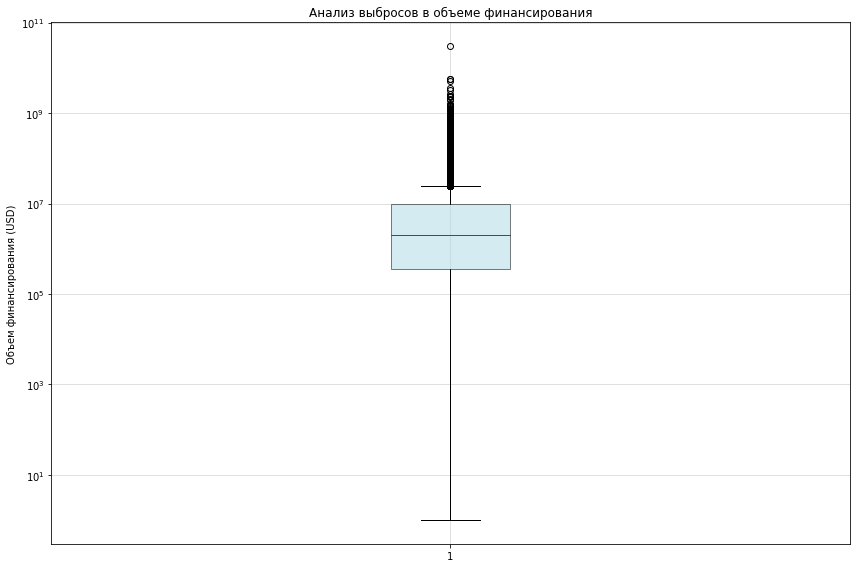

In [35]:
# Строим Boxplot с логарифмической шкалой для лучшей визуализации
plt.figure(figsize=(12, 8))

box_plot = plt.boxplot(cb_investments['funding_total_usd'], 
                       vert=True, 
                       patch_artist=True,
                       boxprops=dict(facecolor='lightblue', alpha=0.5),
                       medianprops=dict(color='red'))

plt.ylabel('Объем финансирования (USD)')
plt.title('Анализ выбросов в объеме финансирования')
plt.yscale('log')
plt.grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

In [36]:
# Определяем типичное значение (по медиане)
typical_value = cb_investments['funding_total_usd'].median()
print(f'Типичный размер общего финансирования: {typical_value}')

# Определяем интервал типичных значений по IQR
Q1 = cb_investments['funding_total_usd'].quantile(0.25)
Q3 = cb_investments['funding_total_usd'].quantile(0.75)
IQR = Q3 - Q1

# Границы типичных значений
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print()
print(f'Интервал, в котором лежат типичные значения: от {lower_bound} до {upper_bound}')

Типичный размер общего финансирования: 2000000.0

Интервал, в котором лежат типичные значения: от -14125000.0 до 24475000.0


In [37]:
# Определяем аномалии для каждой из трех категорий
anomaly_info = {}

# Группы для анализа
categories = {
    'massive': cb_investments[~cb_investments['market'].isin(['mid', 'niche'])]['market'].unique(),
    'mid': ['mid'],
    'niche': ['niche']
}

for category_name, segments in categories.items():
    if category_name == 'massive':
        # Для массовых сегментов анализируем каждый отдельно
        category_data = cb_investments[~cb_investments['market'].isin(['mid', 'niche'])]
    else:
        # Для средних и нишевых анализируем как одну группу
        category_data = cb_investments[cb_investments['market'] == category_name]
    
    if len(category_data) == 0:
        continue
    
    # Вычисляем IQR для категории
    Q1 = category_data['funding_total_usd'].quantile(0.25)
    Q3 = category_data['funding_total_usd'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Определяем границы
    lower_bound = max(0, Q1 - 1.5 * IQR)
    upper_bound = Q3 + 1.5 * IQR
    
    # Находим аномалии
    anomalies = category_data[(category_data['funding_total_usd'] < lower_bound) | 
                             (category_data['funding_total_usd'] > upper_bound)]
    
    anomaly_info[category_name] = {
        'total_companies': len(category_data),
        'anomalies_count': len(anomalies),
        'anomalies_percentage': (len(anomalies) / len(category_data)) * 100 if len(category_data) > 0 else 0,
        'lower_bound': lower_bound,
        'upper_bound': upper_bound,
        'median': category_data['funding_total_usd'].median()
    }
    
    print(f'{category_name}')
    print(f'  Всего компаний: {len(category_data):,}')
    print(f'  Аномалий: {len(anomalies):,} ({(len(anomalies) / len(category_data)) * 100:.2f}%)')

# Помечаем аномальные компании в датасете
def mark_anomalies(row):
    market = row['market']
    funding = row['funding_total_usd']
    
    # Определяем категорию
    if market == 'mid':
        category = 'mid'
    elif market == 'niche':
        category = 'niche'
    else:
        category = 'massive'
    
    # Проверяем, является ли значение аномалией для категории
    if category in anomaly_info:
        bounds = anomaly_info[category]
        return not (bounds['lower_bound'] <= funding <= bounds['upper_bound'])
    else:
        return False

cb_investments['is_anomaly'] = cb_investments.apply(mark_anomalies, axis=1)


massive
  Всего компаний: 33,733
  Аномалий: 4,388 (13.01%)
mid
  Всего компаний: 3,839
  Аномалий: 556 (14.48%)
niche
  Всего компаний: 3,333
  Аномалий: 477 (14.31%)


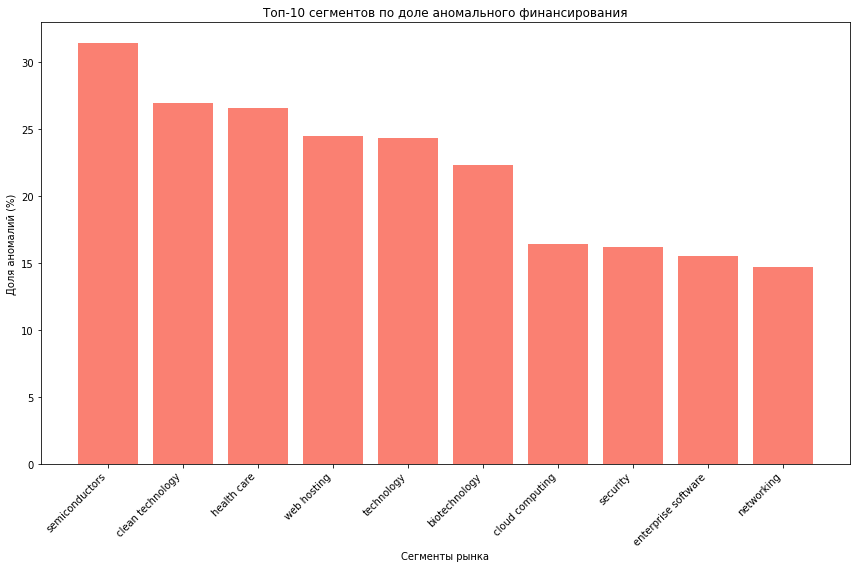

Топ-10 сегментов по доле аномального финансирования:
 1. semiconductors: 31.40% аномалий (152 из 484 компаний)
 2. clean technology: 26.95% аномалий (318 из 1180 компаний)
 3. health care: 26.58% аномалий (315 из 1185 компаний)
 4. web hosting: 24.53% аномалий (104 из 424 компаний)
 5. technology: 24.37% аномалий (58 из 238 компаний)
 6. biotechnology: 22.31% аномалий (801 из 3590 компаний)
 7. cloud computing: 16.45% аномалий (25 из 152 компаний)
 8. security: 16.23% аномалий (92 из 567 компаний)
 9. enterprise software: 15.50% аномалий (214 из 1381 компаний)
10. networking: 14.69% аномалий (21 из 143 компаний)


In [38]:
# Создаем график топ-10 сегментов по доле аномалий
plt.figure(figsize=(12, 8))

# Считаем долю аномалий для каждого сегмента
segment_anomaly_rates = {}

for segment in cb_investments['market'].unique():
    if pd.isna(segment):
        continue
    segment_data = cb_investments[cb_investments['market'] == segment]
    segment_anomalies = segment_data['is_anomaly'].sum()
    segment_total = len(segment_data)
    anomaly_rate = (segment_anomalies / segment_total) * 100 if segment_total > 0 else 0
    segment_anomaly_rates[segment] = {
        'rate': anomaly_rate,
        'anomalies': segment_anomalies,
        'total': segment_total
    }

# Создаем DataFrame и сортируем по убыванию
anomaly_df = pd.DataFrame.from_dict(segment_anomaly_rates, orient='index')
anomaly_df = anomaly_df.sort_values('rate', ascending=False)

# Берем топ-10
top_10_segments = anomaly_df.head(10)

# Строим столбчатую диаграмму
bars = plt.bar(range(len(top_10_segments)), top_10_segments['rate'], color='salmon')

# Настройки графика
plt.xlabel('Сегменты рынка')
plt.ylabel('Доля аномалий (%)')
plt.title('Топ-10 сегментов по доле аномального финансирования')
plt.xticks(range(len(top_10_segments)), top_10_segments.index, rotation=45, ha='right')

plt.tight_layout()
plt.show()

# Выводим числовые данные топ-10
print("Топ-10 сегментов по доле аномального финансирования:")
for i, (segment, data) in enumerate(top_10_segments.iterrows(), 1):
    print(f"{i:2d}. {segment}: {data['rate']:.2f}% аномалий "
          f"({int(data['anomalies'])} из {int(data['total'])} компаний)")



По диаграмме размаха, отображающей размер общего финансирования, видно, что присутствует множество выбросов в данных (т.е. аномально большой размер финансирования).

Типичный размер общего финансирования для одной компании равен 2000000$. При этом интервал типичных значений находится в диапазоне от -14125000 до 24475000.

Наибольшую долю аномалий демонстрируют средние сегменты (14.48%), за ними следуют нишевые (14.31%) и массовые (13.01%).

Среди конкретных сегментов лидерами по аномальному финансированию являются semiconductors (31.40% аномалий), clean technology (26.95%) и health care (26.58%).

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

In [39]:
# Проверяем полноту данных за 2014 год
companies_2014 = cb_investments[cb_investments['mid_funding_at'].dt.year == 2014]
print(f"Всего компаний с финансированием в 2014 году: {len(companies_2014)}")
print()
# Проверяем распределение по месяцам 2014 года
if len(companies_2014) > 0:
    monthly_2014 = companies_2014['mid_funding_at'].dt.month.value_counts().sort_index()
    print(f"Распределение компаний по месяцам 2014 года:")
    for month, count in monthly_2014.items():
        print(f"  Месяц {month}: {count} компаний")



Всего компаний с финансированием в 2014 году: 6619

Распределение компаний по месяцам 2014 года:
  Месяц 1: 739 компаний
  Месяц 2: 600 компаний
  Месяц 3: 676 компаний
  Месяц 4: 645 компаний
  Месяц 5: 600 компаний
  Месяц 6: 740 компаний
  Месяц 7: 687 компаний
  Месяц 8: 559 компаний
  Месяц 9: 547 компаний
  Месяц 10: 497 компаний
  Месяц 11: 306 компаний
  Месяц 12: 23 компаний


In [40]:
# Исключаем компании с аномальным финансированием
print(f"Исходное количество компаний: {len(cb_investments):,}")
companies_without_anomalies = cb_investments[~cb_investments['is_anomaly']]
print(f"После исключения аномалий: {len(companies_without_anomalies):,}")
print(f"Удалено аномальных компаний: {len(cb_investments) - len(companies_without_anomalies):,}")

Исходное количество компаний: 40,905
После исключения аномалий: 35,484
Удалено аномальных компаний: 5,421


In [41]:
# Проверим количество раундов по годам
cb_investments['funding_year'] = cb_investments['mid_funding_at'].dt.year
rounds_by_year = cb_investments.groupby('funding_year')['funding_rounds'].sum()

print("Общее количество раундов по годам:")
rounds_by_year = rounds_by_year.sort_index()
for year, total_rounds in rounds_by_year.items():
    if not pd.isna(year):
        print(f"  {int(year)}: {int(total_rounds):,} раундов")

# Определим годы с 50+ раундами
active_years = rounds_by_year[rounds_by_year >= 50].index
print(f"\nГоды с 50+ раундами финансирования: {sorted([int(y) for y in active_years if not pd.isna(y)])}")

# Теперь выбираем компании, которые получали финансирование в эти активные годы
final_dataset = companies_without_anomalies[
    companies_without_anomalies['mid_funding_at'].dt.year.isin(active_years)
]

print(f"\nФильтрация по активным годам:")
print(f"Компаний после фильтрации: {len(final_dataset):,}")
print(f"Процент от исходного датасета: {(len(final_dataset) / len(cb_investments)) * 100:.2f}%")

Общее количество раундов по годам:
  1921: 1 раундов
  1960: 2 раундов
  1979: 1 раундов
  1982: 3 раундов
  1983: 1 раундов
  1984: 2 раундов
  1985: 3 раундов
  1987: 2 раундов
  1989: 1 раундов
  1990: 1 раундов
  1992: 5 раундов
  1993: 1 раундов
  1994: 4 раундов
  1995: 9 раундов
  1996: 11 раундов
  1997: 13 раундов
  1998: 28 раундов
  1999: 118 раундов
  2000: 247 раундов
  2001: 163 раундов
  2002: 164 раундов
  2003: 260 раундов
  2004: 410 раундов
  2005: 1,446 раундов
  2006: 2,914 раундов
  2007: 4,845 раундов
  2008: 6,024 раундов
  2009: 7,003 раундов
  2010: 8,266 раундов
  2011: 9,248 раундов
  2012: 11,352 раундов
  2013: 14,276 раундов
  2014: 7,757 раундов

Годы с 50+ раундами финансирования: [1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]

Фильтрация по активным годам:
Компаний после фильтрации: 35,437
Процент от исходного датасета: 86.63%


Анализ показал, что данные за 2014 год неполные - наблюдается значительное снижение активности в конце года.

Из исходного датасета было исключено 5421 аномальных компаний (13.25%), после чего осталось 35437 компаний.

С 1999 по 2014 год было зафиксировано 50 и более раундов финансирования, что составляет 86.63% от исходного датасета.

### 3.3. Анализ типов финансирования по объёму и популярности



In [42]:
# Определим столбцы с типами финансирования
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

# Рассчитаем общие объемы по каждому типу финансирования
funding_amounts = {}
funding_popularity = {}

for funding_type in funding_types:
    if funding_type in final_dataset.columns:
        total_amount = final_dataset[funding_type].sum()
        popularity = len(final_dataset[final_dataset[funding_type] > 0])
        funding_amounts[funding_type] = total_amount
        funding_popularity[funding_type] = popularity

amounts_series = pd.Series(funding_amounts).sort_values(ascending=False)
popularity_series = pd.Series(funding_popularity).sort_values(ascending=False)

print("Объемы финансирования по типам (в порядке убывания):")
for funding_type, amount in amounts_series.items():
    companies_count = funding_popularity[funding_type]
    print(f"{funding_type}: {amount:,.0f} {companies_count:,} компаний")

print(f"\nПопулярность типов финансирования (в порядке убывания):")
for funding_type, count in popularity_series.items():
    total_amount = funding_amounts[funding_type]
    print(f"{funding_type}: {count:,} компаний ({total_amount:,.0f} всего)")

Объемы финансирования по типам (в порядке убывания):
venture: 107,987,282,739 18,681 компаний
seed: 9,640,651,201 13,475 компаний
debt_financing: 5,788,957,773 3,062 компаний
private_equity: 3,215,978,473 587 компаний
angel: 2,592,074,963 2,989 компаний
undisclosed: 2,033,886,606 817 компаний
grant: 1,835,211,113 991 компаний
post_ipo_equity: 919,775,907 132 компаний
convertible_note: 522,225,635 508 компаний
equity_crowdfunding: 278,717,319 520 компаний
product_crowdfunding: 202,935,639 207 компаний
post_ipo_debt: 147,809,099 23 компаний
secondary_market: 45,285,796 7 компаний

Популярность типов финансирования (в порядке убывания):
venture: 18,681 компаний (107,987,282,739 всего)
seed: 13,475 компаний (9,640,651,201 всего)
debt_financing: 3,062 компаний (5,788,957,773 всего)
angel: 2,989 компаний (2,592,074,963 всего)
grant: 991 компаний (1,835,211,113 всего)
undisclosed: 817 компаний (2,033,886,606 всего)
private_equity: 587 компаний (3,215,978,473 всего)
equity_crowdfunding: 520 ко

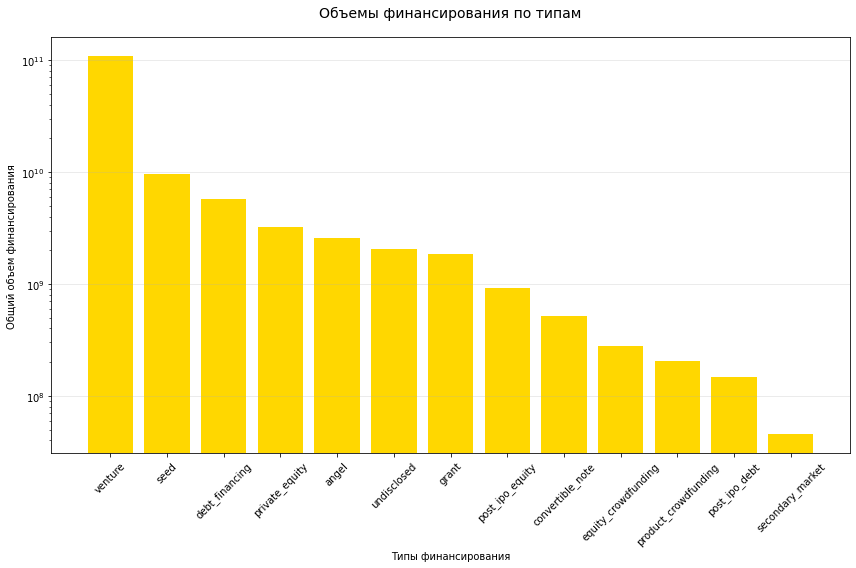

In [43]:
# График объемов финансирования
plt.figure(figsize=(12, 8))

sorted_amounts = amounts_series.sort_values(ascending=False)

bars = plt.bar(range(len(sorted_amounts)), sorted_amounts.values, color='gold')

plt.xlabel('Типы финансирования')
plt.ylabel('Общий объем финансирования')
plt.title('Объемы финансирования по типам', fontsize=14, pad=20)

# Логарифмическая шкала по Y для лучшей визуализации
plt.yscale('log')

plt.xticks(range(len(sorted_amounts)), sorted_amounts.index, rotation=45)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()



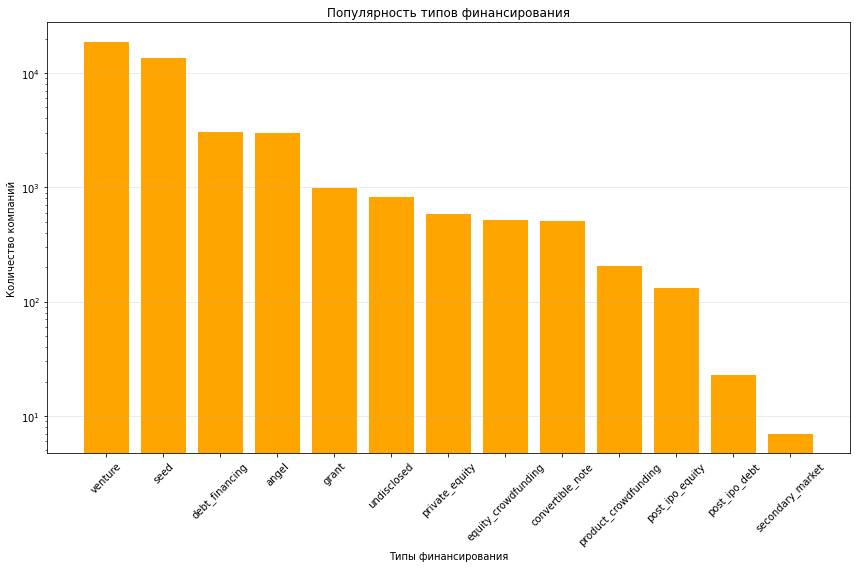

In [44]:
# График популярности типов финансирования
plt.figure(figsize=(12, 8))

sorted_popularity = popularity_series.sort_values(ascending=False)

bars = plt.bar(range(len(sorted_popularity)), sorted_popularity.values, color='orange')

plt.xlabel('Типы финансирования')
plt.ylabel('Количество компаний')
plt.title('Популярность типов финансирования')

# Логарифмическая шкала по Y для лучшей визуализации
plt.yscale('log')

plt.xticks(range(len(sorted_popularity)), sorted_popularity.index, rotation=45)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

Анализ показал, что самыми объемными по финансированию были такие типы финансирования, как venture, seed и debt_financing, при этом venture значительно превышает другие типы. Самыми популярными типами так же являются venture, seed и debt_financing.

Типы post_ipo_equity и private_equity имеют достаточно высокий объем финансирования, при этом не обладая высокой популярностью. 


Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

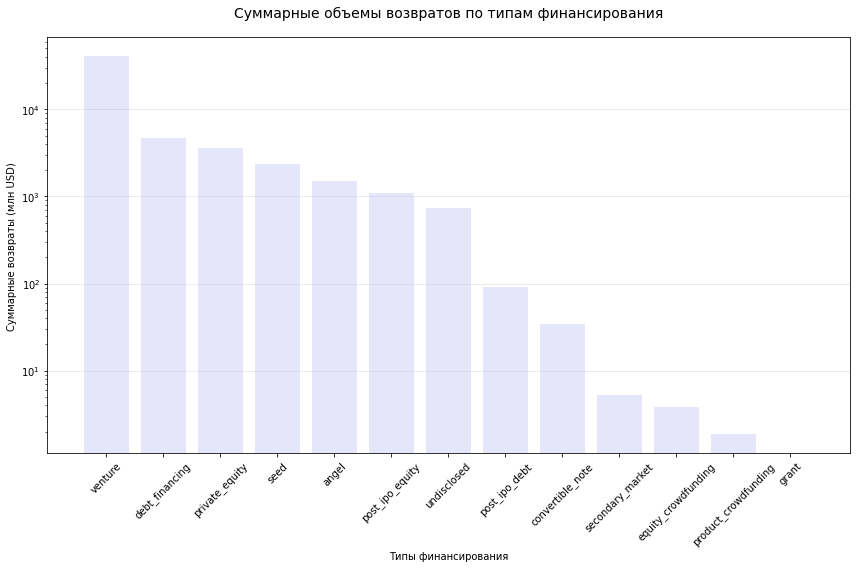

In [45]:
# Рассчитаем суммарные объемы возвратов за весь период для каждого типа финансирования
returns_totals = cb_returns.sum()  # Суммируем по всем годам

returns_sorted = returns_totals.sort_values(ascending=False)

plt.figure(figsize=(12, 8))

bars = plt.bar(range(len(returns_sorted)), returns_sorted.values, color='lavender')

plt.xlabel('Типы финансирования')
plt.ylabel('Суммарные возвраты (млн USD)')
plt.title('Суммарные объемы возвратов по типам финансирования', fontsize=14, pad=20)

# Логарифмическая шкала по Y для лучшей визуализации
plt.yscale('log')

plt.xticks(range(len(returns_sorted)), returns_sorted.index, rotation=45)

plt.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


Наибольшие суммарные объемы возвратов были у таких типов, как venture, debt_financing и private_equity. Наименьшие - product_crowdfunding и grant.

---

## 4️⃣ Анализ динамики

### 4.1 Динамика предоставления финансирования по годам



In [46]:
# Рассчитываем средний объём одного раунда финансирования для каждой компании
final_dataset = final_dataset.copy()  # Создаем копию датасета
final_dataset['avg_funding_per_round'] = final_dataset['funding_total_usd'] / final_dataset['funding_rounds']


In [47]:
# Выделяем год из mid_funding_at
final_dataset['funding_year'] = final_dataset['mid_funding_at'].dt.year

# Группируем данные по годам
yearly_data = final_dataset.groupby('funding_year').agg({
    'avg_funding_per_round': 'median',
    'funding_rounds': 'sum'
}).reset_index()

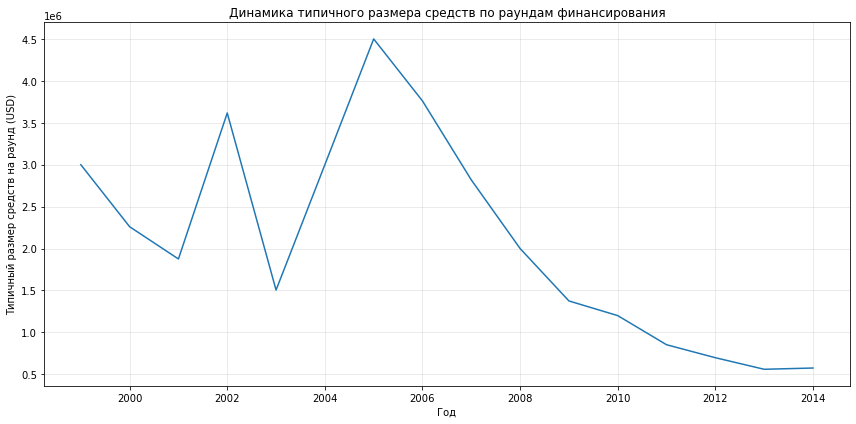

In [48]:
# График динамики типичного размера средств по раундам
plt.figure(figsize=(12, 6))
plt.plot(yearly_data['funding_year'], yearly_data['avg_funding_per_round'])
plt.xlabel('Год')
plt.ylabel('Типичный размер средств на раунд (USD)')
plt.title('Динамика типичного размера средств по раундам финансирования')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

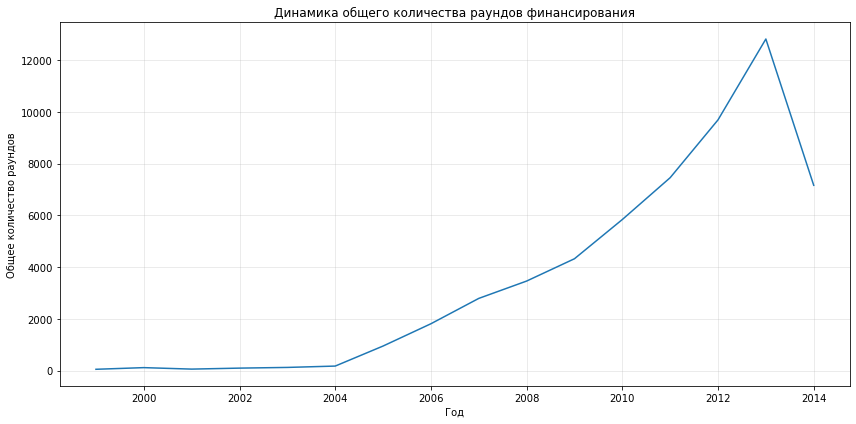

In [49]:
# График динамики общего количества раундов
plt.figure(figsize=(12, 6))
plt.plot(yearly_data['funding_year'], yearly_data['funding_rounds'])
plt.xlabel('Год')
plt.ylabel('Общее количество раундов')
plt.title('Динамика общего количества раундов финансирования')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
# Выводим данные для анализа в более читаемом формате
print("Данные по годам:")
display_data = yearly_data.sort_values('funding_year').copy()
display_data['avg_funding_per_round'] = display_data['avg_funding_per_round'].round(2)
display_data['funding_rounds'] = display_data['funding_rounds'].astype(int)
print(display_data)

Данные по годам:
    funding_year  avg_funding_per_round  funding_rounds
0           1999             3000000.00              52
1           2000             2260233.58             116
2           2001             1875530.50              59
3           2002             3616666.67              97
4           2003             1505000.00             124
5           2004             3000000.00             176
6           2005             4500000.00             950
7           2006             3760000.00            1811
8           2007             2818292.33            2790
9           2008             2000000.00            3460
10          2009             1375000.00            4322
11          2010             1200000.00            5837
12          2011              852670.75            7453
13          2012              698000.00            9686
14          2013              560000.00           12810
15          2014              575000.00            7159


Типичный размер средств, собранных в рамках одного раунда, был максимальным в 2005 году.

В 2014 году количество раундов значительно снизилось (с 12810 в 2013 году до 7159 в 2014 году), количество средств немного увеличилось по сравнению с 2013 годом (575,000 против 560,000). С 2005 года наблюдается тенденция снижения количества средств финансирования.

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов



In [51]:
# Создаем сводную таблицу по годам и сегментам (только массовые)
pivot_table = final_dataset[~final_dataset['market'].isin(['niche', 'mid'])].pivot_table(
    values='funding_total_usd',
    index='market',
    columns='funding_year',
    aggfunc='sum',
    fill_value=0
)

In [52]:
# Отбираем сегменты с ростом в 2014 году по сравнению с 2013
growth_segments = []
for segment in pivot_table.index:
    if pivot_table.loc[segment, 2014] > pivot_table.loc[segment, 2013] and pivot_table.loc[segment, 2013] > 0:
        growth_segments.append(segment)
        
# Выводим топ сегментов по росту финансирования
print("Топ сегментов по росту в 2014 году по сравнению с 2013:")
segment_growth_data = []
for segment in growth_segments:
    growth_2014 = pivot_table.loc[segment, 2014]
    growth_2013 = pivot_table.loc[segment, 2013]
    growth_rate = ((growth_2014 - growth_2013) / growth_2013 * 100)
    segment_growth_data.append((segment, growth_rate, growth_2013, growth_2014))

for i in range(min(10, len(segment_growth_data))):
    segment, growth_rate, growth_2013, growth_2014 = segment_growth_data[i]
    print(f"{segment}: {growth_2013:,.0f} → {growth_2014:,.0f}      рост = {growth_rate:.1f}%")

Топ сегментов по росту в 2014 году по сравнению с 2013:
apps: 79,114,136 → 147,251,866      рост = 86.1%
fashion: 167,411,631 → 177,075,192      рост = 5.8%
internet: 83,132,096 → 130,655,982      рост = 57.2%
medical: 64,469,424 → 175,236,064      рост = 171.8%
news: 118,475,497 → 129,478,651      рост = 9.3%
nonprofits: 71,155,457 → 72,341,299      рост = 1.7%
real estate: 172,350,754 → 193,467,364      рост = 12.3%
saas: 115,100,858 → 152,807,752      рост = 32.8%
sports: 36,208,524 → 58,456,511      рост = 61.4%
startups: 63,032,467 → 100,501,837      рост = 59.4%


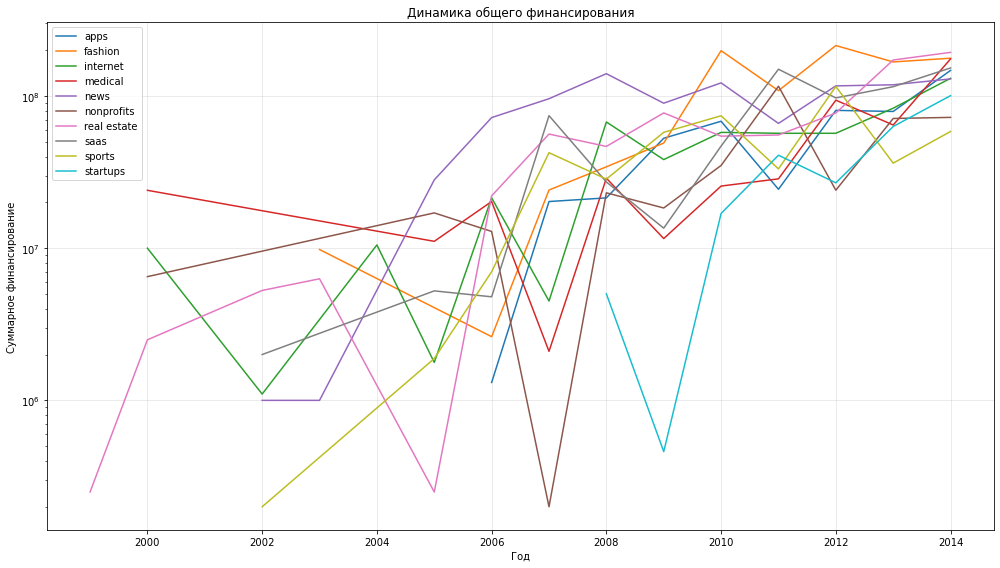

In [53]:
# Фильтруем данные для графика
growth_data = final_dataset[final_dataset['market'].isin(growth_segments)]

# Группируем по сегментам и годам
segment_yearly = growth_data.groupby(['market', 'funding_year'])['funding_total_usd'].sum().reset_index()

# Строим график для топ-10 сегментов по росту
plt.figure(figsize=(14, 8))

top_10_segments = []
for item in segment_growth_data[:10]:
    top_10_segments.append(item[0])

for segment in top_10_segments:
    segment_data = segment_yearly[segment_yearly['market'] == segment]
    if not segment_data.empty:
        plt.plot(segment_data['funding_year'], segment_data['funding_total_usd'], 
                label=segment)

plt.xlabel('Год')
plt.ylabel('Суммарное финансирование')
plt.title('Динамика общего финансирования')
plt.legend()
plt.grid(True, alpha=0.3)
plt.yscale('log')
plt.tight_layout()
plt.show()

Сегмент medical демонстрирует наибольший рост финансирования (171.8%) в 2014 году по сравнению с 2013. Также высокий рост показывают apps (86.1%) и sports (61.4%).

На основе графика можно сделать вывод, что такие сегменты, как news и fashion показывают наиболее быстрый и уверенный рост.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

In [54]:
# Приводим возвраты к долларам (умножаем на 1,000,000)
cb_returns_dollars = cb_returns * 1000000

# Рассчитываем годовые суммы финансирования по типам из основного датасета
funding_types = ['seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note', 
                'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity', 
                'post_ipo_debt', 'secondary_market', 'product_crowdfunding']

# Группируем данные по годам и считаем суммы по каждому типу финансирования
yearly_funding = final_dataset.groupby(final_dataset['mid_funding_at'].dt.year)[funding_types].sum().fillna(0)
yearly_funding.index = yearly_funding.index.astype(int)

In [55]:
# Создаем DataFrame для хранения долей возвратов
returns_ratio = pd.DataFrame(index=cb_returns_dollars.index, columns=funding_types)

# Рассчитываем долю возвратов для каждого года и типа финансирования
for funding_type in funding_types:
    if funding_type in cb_returns_dollars.columns:
        for year in cb_returns_dollars.index:
            returned = cb_returns_dollars.loc[year, funding_type]
            invested = yearly_funding.loc[year, funding_type] if year in yearly_funding.index else 0
            
  # Проверяем, есть ли инвестиции
            if invested > 0 and returned >= 0:
                ratio = returned / invested
                # Отрезаем аномальные значения (больше 1 = 100%)
                if ratio <= 1:
                    returns_ratio.loc[year, funding_type] = ratio
                else:
                    returns_ratio.loc[year, funding_type] = np.nan
            else:
                returns_ratio.loc[year, funding_type] = np.nan


In [56]:
# Выводим средние значения по каждому типу финансирования
print("Средняя доля возвратов по типам финансирования:")
for funding_type in funding_types:
    if funding_type in returns_ratio.columns:
        avg_return = returns_ratio[funding_type].mean()
        if not np.isnan(avg_return):
            print(f"{funding_type}: {avg_return:.2f} ({avg_return*100:.2f}%)")
        else:
            print(f"{funding_type}: нет данных")

Средняя доля возвратов по типам финансирования:
seed: 0.52 (51.69%)
venture: 0.43 (43.32%)
equity_crowdfunding: 0.07 (7.00%)
undisclosed: 0.47 (47.29%)
convertible_note: 0.10 (10.33%)
debt_financing: 0.63 (63.44%)
angel: 0.53 (53.06%)
grant: 0.00 (0.00%)
private_equity: 0.49 (49.31%)
post_ipo_equity: 0.51 (50.50%)
post_ipo_debt: 0.43 (42.91%)
secondary_market: 0.09 (9.10%)
product_crowdfunding: 0.03 (2.76%)


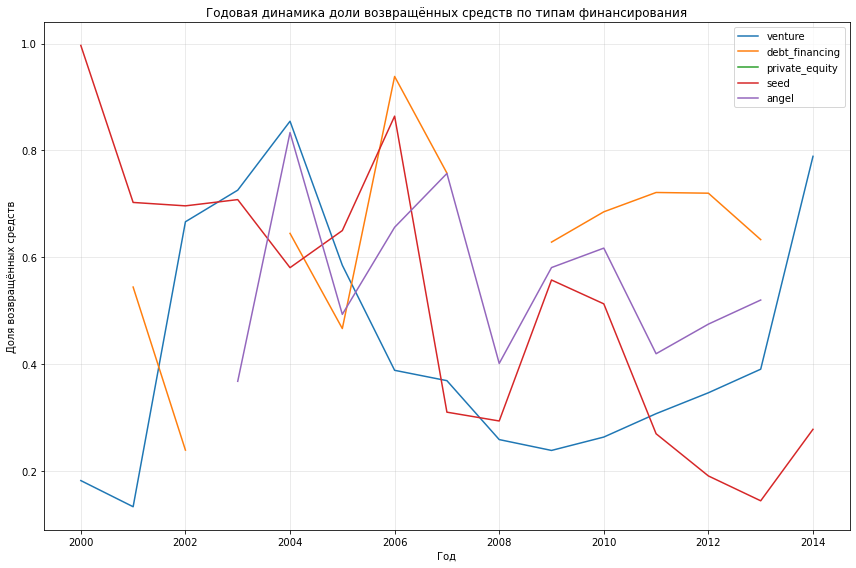

In [57]:
plt.figure(figsize=(12, 8))

selected_funding_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']

colors = plt.cm.Set1(np.linspace(0, 1, len(selected_funding_types)))

for i, funding_type in enumerate(selected_funding_types):
    if funding_type in returns_ratio.columns:
        plt.plot(returns_ratio.index, returns_ratio[funding_type], label=funding_type)

plt.xlabel('Год')
plt.ylabel('Доля возвращённых средств')
plt.title('Годовая динамика доли возвращённых средств по типам финансирования')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Для выбранных типов финансирования наблюдается нестабильная динамика по возращенным средствам.

Из всех представленных типов, angel демонстрирует наиболее устойчивый показатель возвратности, так как линия держится на относительно стабильном уровне, несмотря на скачки.

---


## 🏆 Итоговый вывод и рекомендации

📊 **Итоги проекта**

- Выполненные шаги:
  - Предобработка данных - удалены дубликаты, пропуски, аномалии, исправлены типы данных
  - Инжиниринг признаков - созданы группы компаний по срокам финансирования и классификация сегментов рынка
  - Анализ выбросов - выявлены и удалены аномальные компании, определены сегменты с высокой долей аномалий
  - Анализ динамики - исследована динамика по годам, рост сегментов и возвратность инвестиций
  
- Основные выводы:
  - структура рынка: большинство компаний получают единичное финансирование, а самые крупные инвестиции сосредоточены в компаниях с длительным сроком финансирования.

  - типы финансирования: venture (107 млрд, 18,681 компания) и seed (9.6 млрд, 13,475 компаний) доминируют по объемам и популярности

  - перспективные сегменты: medical, apps и sports (самый высокий рост в 2014 году по сравнению с 2013), news и fashion (наиболее уверенный рост).

  - возвратность инвестиций: типы финансирования debt_financing и angel обеспечивают большую и устойчивую возвратность.
  
- Согласованность выводов:

   - рассматриваемый сегмент medical, получивший самый высокий рост финансирования (171.8%) с 2013 по 2014 года, при этом имеет нестабильную динамику с 2000 года (были резкие спады и скачки). В то же время сегменты news и fashion, имеющие стабильный и уверенный рост за предыдущие года, показывают небольшой рост финансирования с 2013 по 2014 (всего 9.3% и 5.8% соответственно).
    
   - для типа финансирования debt_financing, с самой высокой долей возвратности средств (63.44%), отсутствуют данные по возратности за некоторые года, значит динамика возратности была для него нестабильна.
    
   - при этом тип angel, имеющий относительно стабильную динамику возвратности имеет и достаточно большую долю возратности - 53.06%.

💡 **Рекомендации:**

- На основе анализа динамики роста финансирования в 2014 году по сравнению с 2013, наибольшие показатели были у сегмента medical, также перспективны сегменты apps и sports. Наиболее уверенный рост финансирования (без резких спадов роста) показали сегменты news и fashion.
- Наиболее выигрышным будет тип финансирования debt_financing (по средней доле возвратности средств), а также angel (по наиболее устойчивому показателю возвратности).